In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
df = pd.read_csv('adult.csv')
df.sample(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
1315,31,Private,260782,Some-college,10,Married-civ-spouse,Transport-moving,Husband,White,Male,0,1579,45,El-Salvador,<=50K
3510,38,Private,203836,HS-grad,9,Married-civ-spouse,Sales,Husband,White,Male,3464,0,40,Columbia,<=50K
19697,18,?,118847,HS-grad,9,Never-married,?,Own-child,White,Female,0,0,24,United-States,<=50K
29888,38,Private,175972,Some-college,10,Married-civ-spouse,Other-service,Wife,White,Female,0,0,40,United-States,<=50K
19100,35,Private,241998,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,>50K
11752,44,Private,138077,Bachelors,13,Divorced,Adm-clerical,Unmarried,White,Female,0,0,32,United-States,<=50K
1465,42,Federal-gov,296798,11th,7,Never-married,Tech-support,Not-in-family,White,Male,0,1340,40,United-States,<=50K
12619,64,Self-emp-not-inc,289741,Some-college,10,Married-civ-spouse,Sales,Husband,White,Male,0,0,20,United-States,<=50K
4841,21,Private,163870,Some-college,10,Never-married,Handlers-cleaners,Own-child,White,Male,0,0,30,United-States,<=50K
6796,36,Self-emp-not-inc,245090,Bachelors,13,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,50,Mexico,<=50K


### Data ANALYSIS

In [65]:
print(df.shape)
print(df.info())

(32561, 15)
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB
None


In [66]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [67]:
df.describe(include=object)

C:\Users\theha\AppData\Local\Temp\ipykernel_10532\3998025828.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=object)


,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,32561,32561,32561,32561,32561,32561,32561,32561,32561
unique,9,16,7,15,6,5,2,42,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


- Duplicated Values 24

In [68]:
print(df.duplicated().sum())

24


In [69]:
df = df.drop_duplicates()

In [70]:
print(df.duplicated().sum())

0


- Check Null Values

In [71]:
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

- Workclass Column

In [72]:
df['workclass'].value_counts()

workclass
Private             22673
Self-emp-not-inc     2540
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [73]:
df[df['workclass']=='?']

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
14,51,?,172175,Doctorate,16,Never-married,?,Not-in-family,White,Male,0,2824,40,United-States,>50K
24,61,?,135285,HS-grad,9,Married-civ-spouse,?,Husband,White,Male,0,2603,32,United-States,<=50K
44,71,?,100820,HS-grad,9,Married-civ-spouse,?,Husband,White,Male,0,2489,15,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,?,320084,Bachelors,13,Married-civ-spouse,?,Wife,White,Female,0,0,55,United-States,>50K
32534,30,?,33811,Bachelors,13,Never-married,?,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,?,287372,Doctorate,16,Married-civ-spouse,?,Husband,White,Male,0,0,10,United-States,>50K
32543,41,?,202822,HS-grad,9,Separated,?,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [74]:
df=df.replace('?',np.nan)
df.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     582
income               0
dtype: int64

In [75]:
df['workclass'] = df['workclass'].replace(np.nan,'Unknown')
df['workclass'].isna().sum()

np.int64(0)

In [76]:
df['workclass'].value_counts()

workclass
Private             22673
Self-emp-not-inc     2540
Local-gov            2093
Unknown              1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

- Education Column

In [77]:
df['education'].value_counts()

education
HS-grad         10494
Some-college     7282
Bachelors        5353
Masters          1722
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           645
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           332
1st-4th           166
Preschool          50
Name: count, dtype: int64

- marital.status Column

In [78]:
df['marital.status'].value_counts()

marital.status
Married-civ-spouse       14970
Never-married            10667
Divorced                  4441
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

- occupation column

In [79]:
df['occupation'].value_counts()

occupation
Prof-specialty       4136
Craft-repair         4094
Exec-managerial      4065
Adm-clerical         3768
Sales                3650
Other-service        3291
Machine-op-inspct    2000
Transport-moving     1597
Handlers-cleaners    1369
Farming-fishing       992
Tech-support          927
Protective-serv       649
Priv-house-serv       147
Armed-Forces            9
Name: count, dtype: int64

In [80]:
df['occupation'] = df['occupation'].replace(np.nan,'Unknown')
df['occupation'].value_counts()

occupation
Prof-specialty       4136
Craft-repair         4094
Exec-managerial      4065
Adm-clerical         3768
Sales                3650
Other-service        3291
Machine-op-inspct    2000
Unknown              1843
Transport-moving     1597
Handlers-cleaners    1369
Farming-fishing       992
Tech-support          927
Protective-serv       649
Priv-house-serv       147
Armed-Forces            9
Name: count, dtype: int64

- relationship column

In [81]:
df['relationship'].value_counts()

relationship
Husband           13187
Not-in-family      8292
Own-child          5064
Unmarried          3445
Wife               1568
Other-relative      981
Name: count, dtype: int64

- race column

In [82]:
df['race'].value_counts()

race
White                 27795
Black                  3122
Asian-Pac-Islander     1038
Amer-Indian-Eskimo      311
Other                   271
Name: count, dtype: int64

- sex column

In [83]:
df['sex'].value_counts()

sex
Male      21775
Female    10762
Name: count, dtype: int64

- native.country Column

In [84]:
df['native.country'].value_counts()

native.country
United-States                 29153
Mexico                          639
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Japan                            62
Guatemala                        62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
Greece                           29
France       

In [85]:
df['native.country'] = df['native.country'].replace(np.nan,'Unknown')
df['native.country'].unique()

<StringArray>
[             'United-States',                    'Unknown',
                     'Mexico',                     'Greece',
                    'Vietnam',                      'China',
                     'Taiwan',                      'India',
                'Philippines',            'Trinadad&Tobago',
                     'Canada',                      'South',
         'Holand-Netherlands',                'Puerto-Rico',
                     'Poland',                       'Iran',
                    'England',                    'Germany',
                      'Italy',                      'Japan',
                       'Hong',                   'Honduras',
                       'Cuba',                    'Ireland',
                   'Cambodia',                       'Peru',
                  'Nicaragua',         'Dominican-Republic',
                      'Haiti',                'El-Salvador',
                    'Hungary',                   'Columbia',
          

- income column

In [86]:
df['income'].value_counts()

income
<=50K    24698
>50K      7839
Name: count, dtype: int64

In [87]:
df['income'] = df['income'].map({'<=50K':0, '>50K':1})
df['income'].value_counts()

income
0    24698
1     7839
Name: count, dtype: int64

In [88]:
(df['income'].value_counts()/len(df))*100

income
0    75.907428
1    24.092572
Name: count, dtype: float64

In [89]:
df['fnlwgt'].nunique()

21648

In [90]:
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

### Univariate Analysis

In [91]:
num_cols = df.select_dtypes(include='int64').columns.tolist()
cat_cols = df.select_dtypes(include='str').columns.tolist()

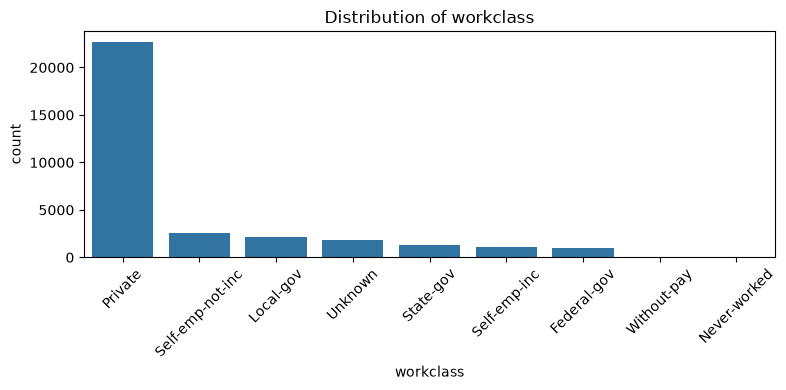

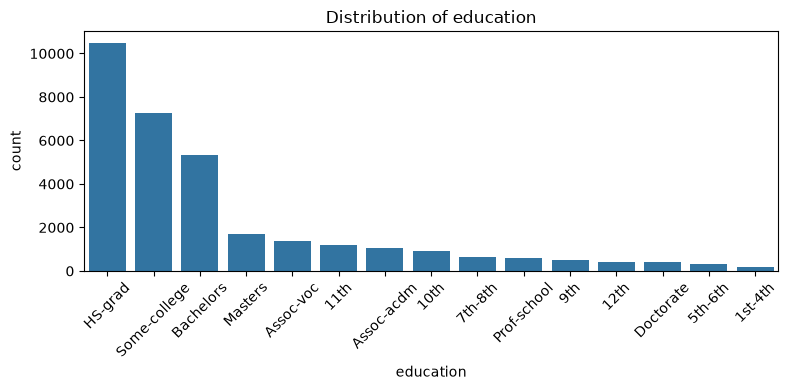

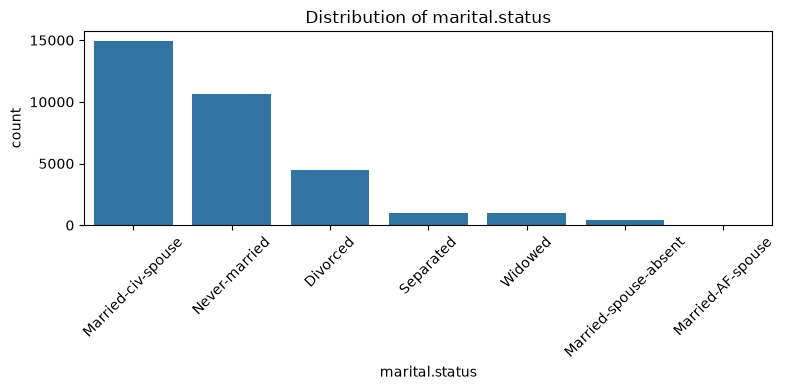

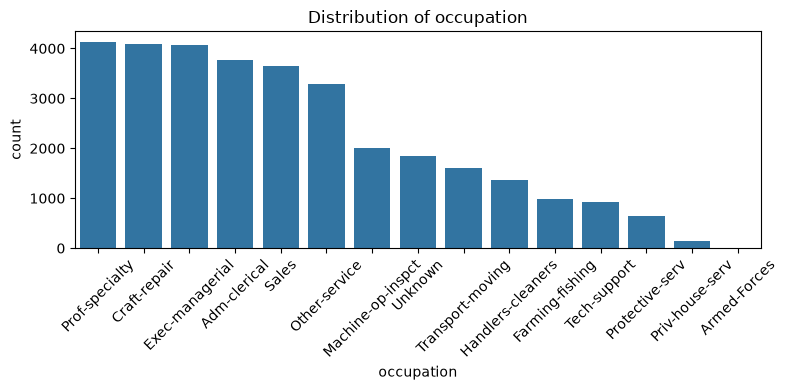

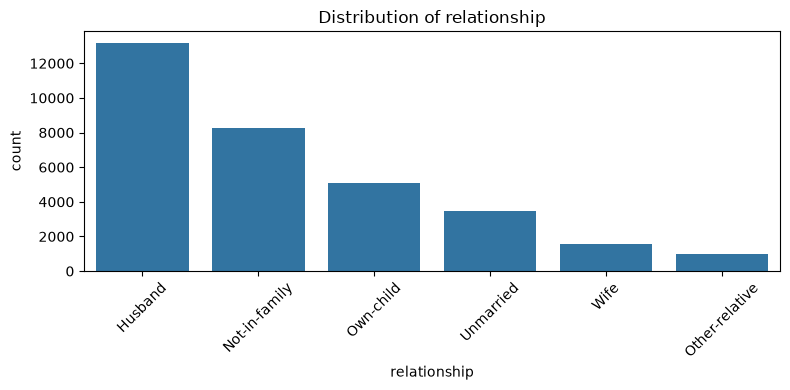

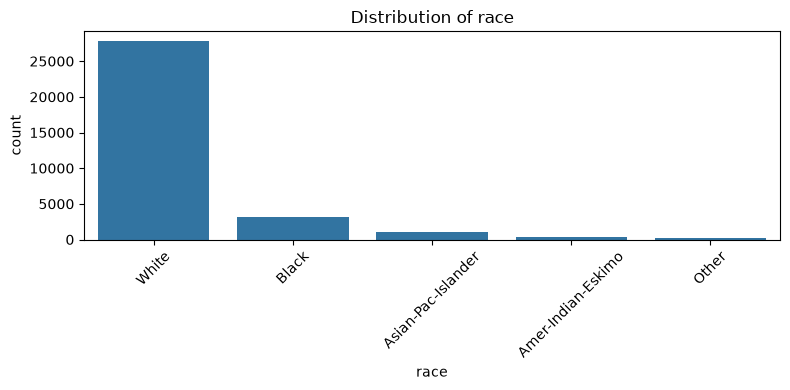

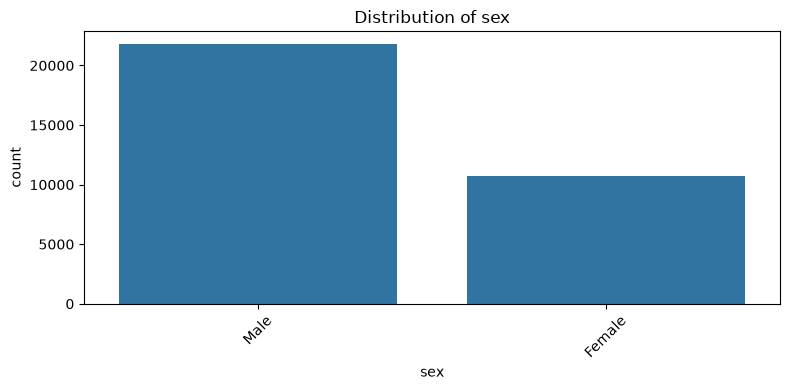

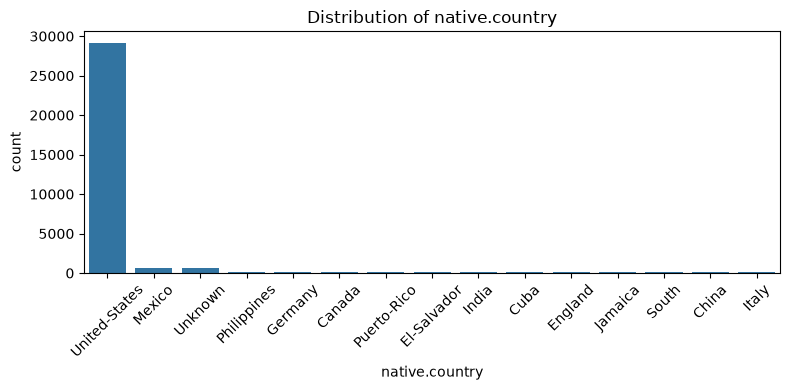

In [92]:
for col in cat_cols:
    if col != "income":
        plt.figure(figsize=(8, 4))
        order = df[col].value_counts().head(15).index
        sns.countplot(data=df, x=col, order=order)
        plt.title(f"Distribution of {col}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

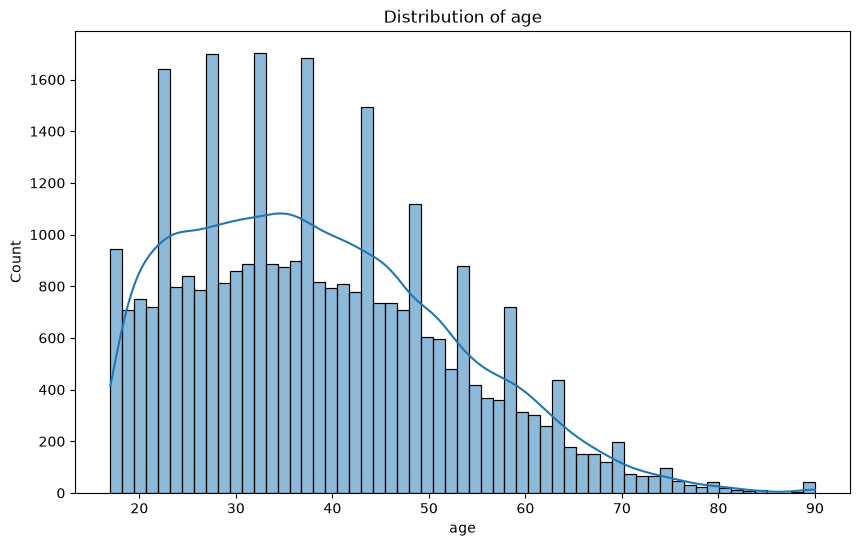

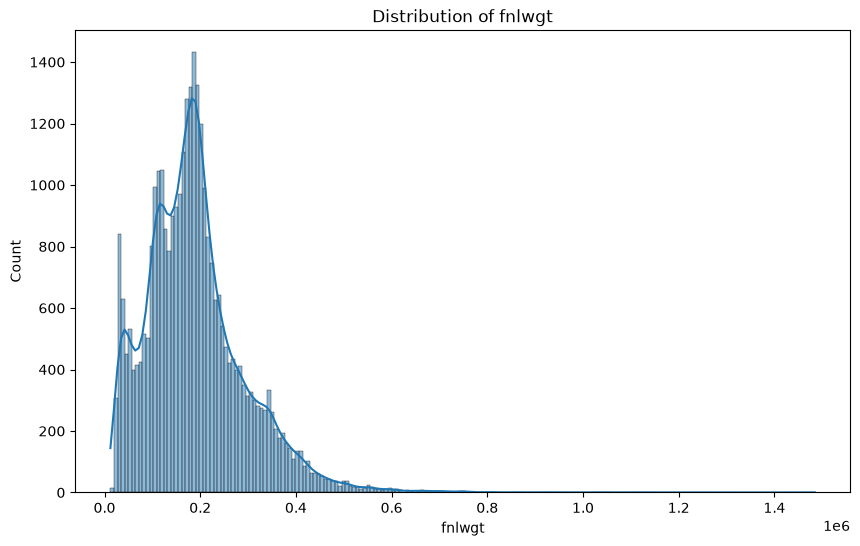

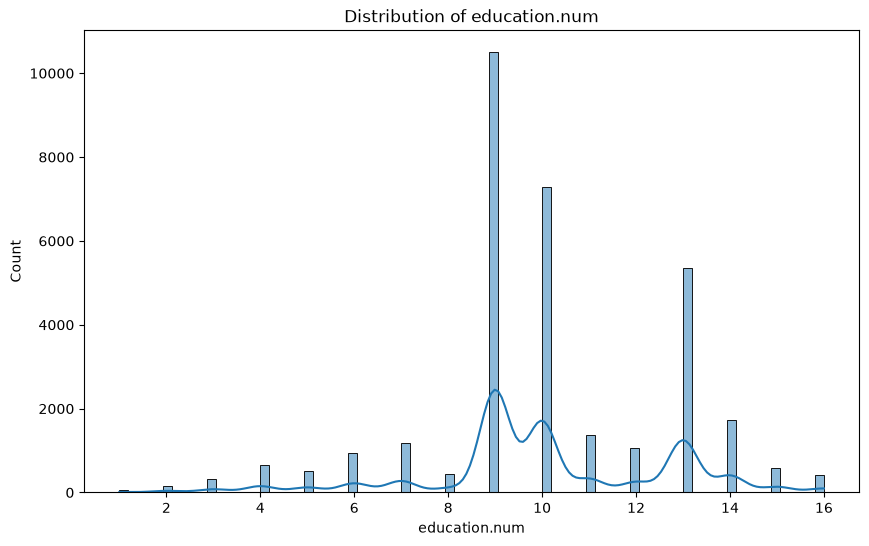

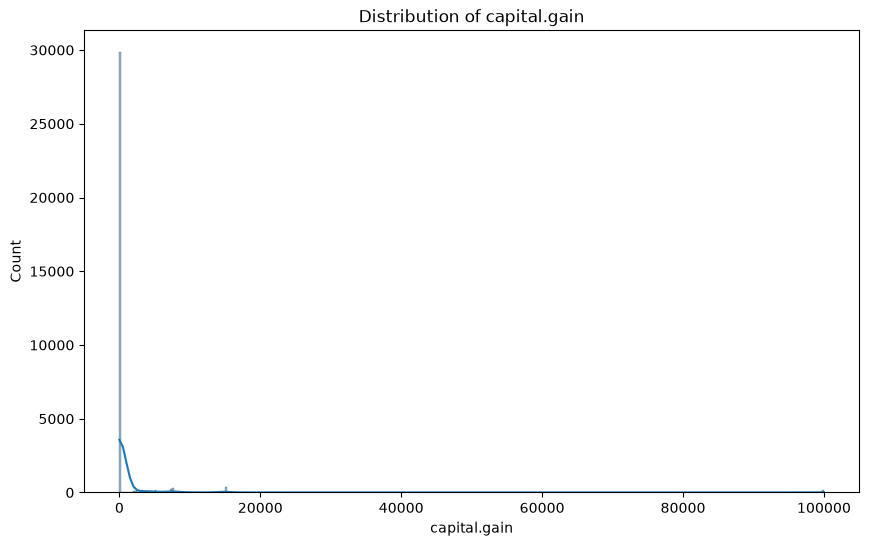

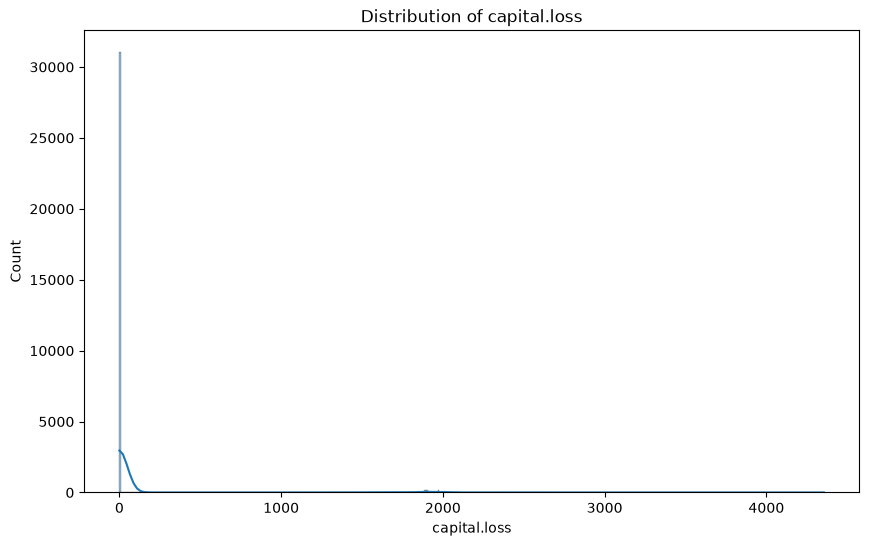

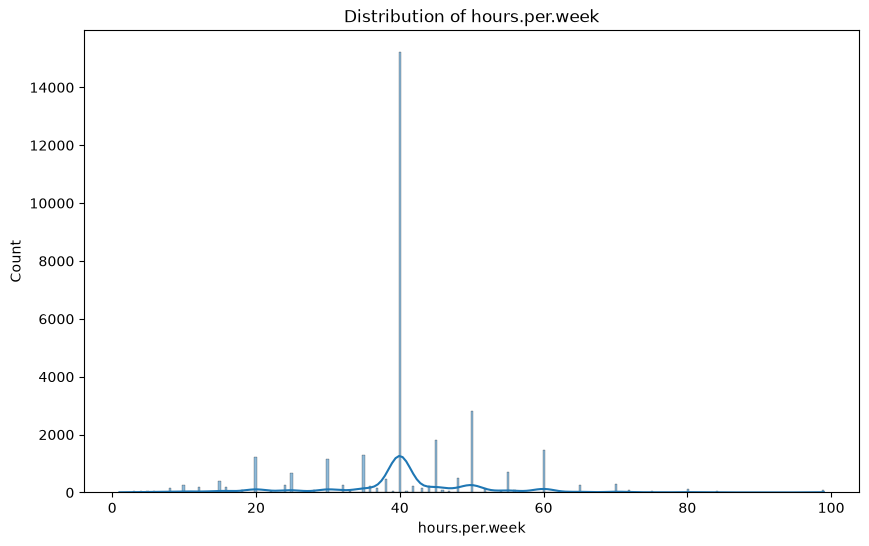

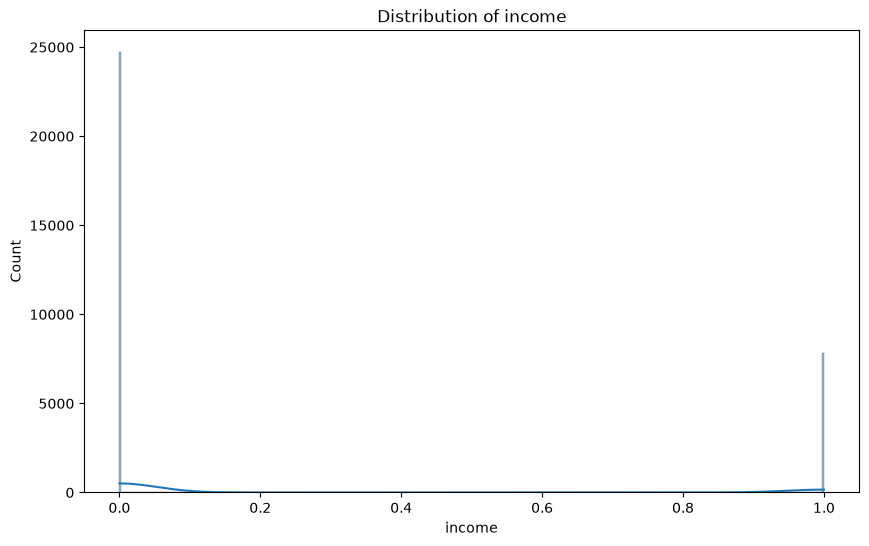

In [93]:
for col in num_cols:
    plt.figure(figsize=(10,6))
    sns.histplot(df[col], kde =True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()


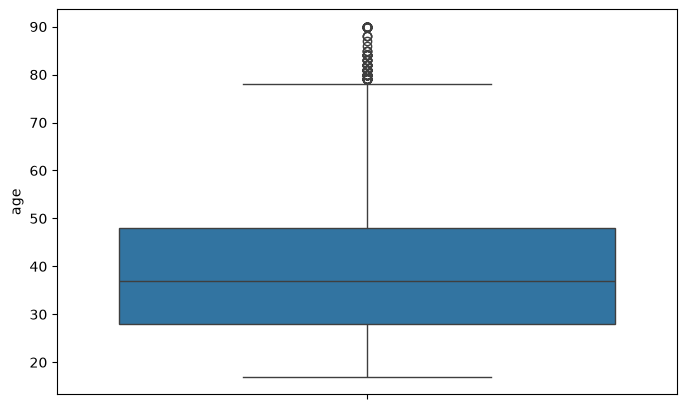

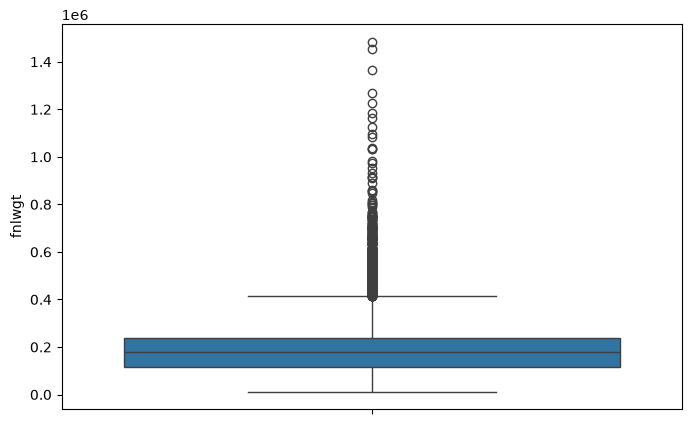

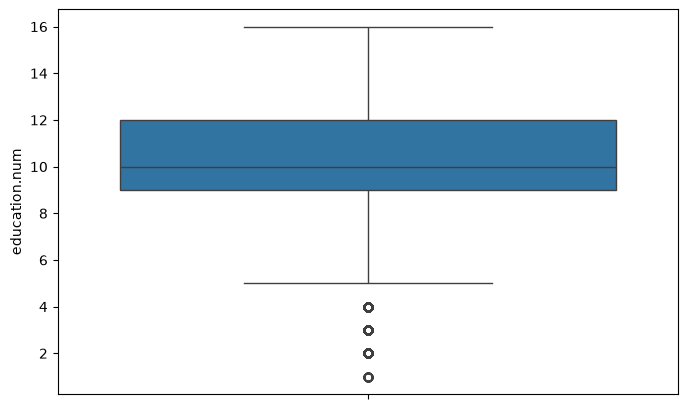

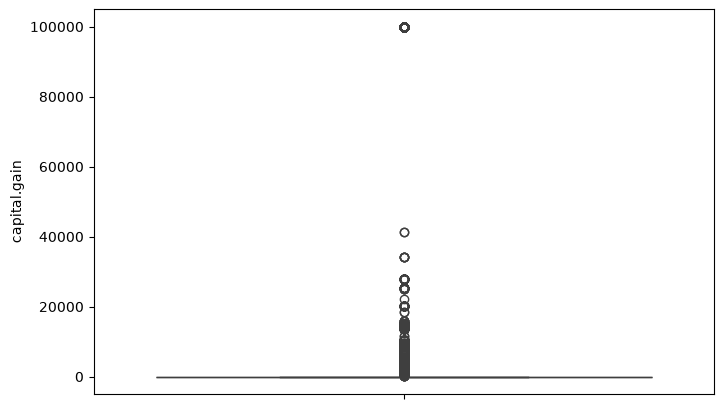

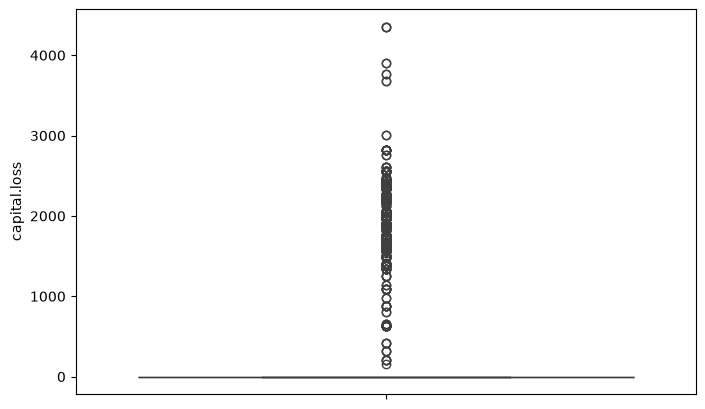

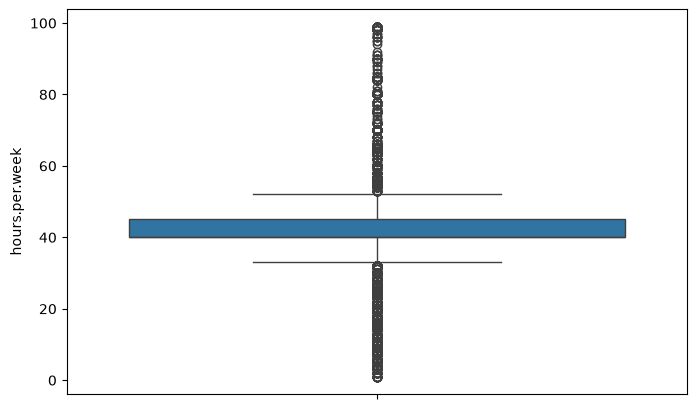

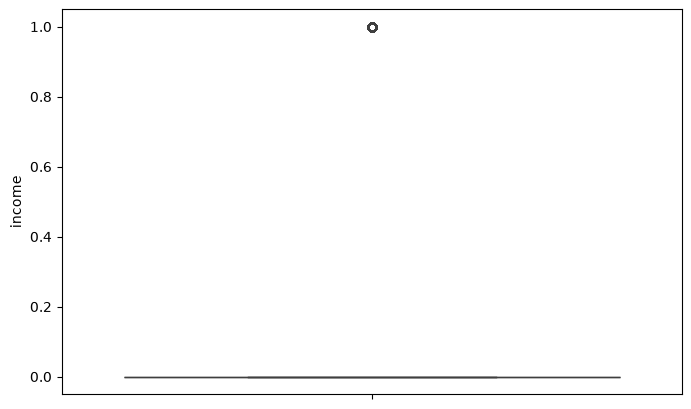

In [94]:
for i in num_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(df[i])

- Outliers

In [95]:
outlier_data = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    counts = ((df[col]<lower) | (df[col]>upper)).sum()

    outlier_data.append({
        'Column':col,
        'Lower Limit':lower,
        'Upper Limit':upper,
        'Number of Outliers':counts
    })
outlier_df = pd.DataFrame(outlier_data)
print(outlier_df)


           Column  Lower Limit  Upper Limit  Number of Outliers
0             age         -2.0         78.0                 142
1          fnlwgt     -60922.0     415742.0                 993
2   education.num          4.5         16.5                1193
3    capital.gain          0.0          0.0                2712
4    capital.loss          0.0          0.0                1519
5  hours.per.week         32.5         52.5                9002
6          income          0.0          0.0                7839


In [96]:
outlier_df['Outliers %'] = (outlier_df['Number of Outliers']/len(df))*100
print(outlier_df)

           Column  Lower Limit  Upper Limit  Number of Outliers  Outliers %
0             age         -2.0         78.0                 142    0.436426
1          fnlwgt     -60922.0     415742.0                 993    3.051910
2   education.num          4.5         16.5                1193    3.666595
3    capital.gain          0.0          0.0                2712    8.335126
4    capital.loss          0.0          0.0                1519    4.668531
5  hours.per.week         32.5         52.5                9002   27.666964
6          income          0.0          0.0                7839   24.092572


- Age Column

In [97]:
df[df['age']>78]['age'].value_counts().sort_index(ascending=False)

age
90    42
88     3
87     1
86     1
85     3
84    10
83     6
82    12
81    20
80    22
79    22
Name: count, dtype: int64

- Education.num Column

In [98]:
df[df['education.num']>16]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income


In [99]:
df[df['education.num']<4.5]['education.num'].value_counts().sort_index(ascending=False)

education.num
4    645
3    332
2    166
1     50
Name: count, dtype: int64

- hours.per.week Column

In [100]:
df[df['hours.per.week']>52.5]['hours.per.week'].value_counts().sort_index(ascending=False)

hours.per.week
99      85
98      11
97       2
96       5
95       2
94       1
92       1
91       3
90      29
89       2
88       2
87       1
86       2
85      13
84      45
82       1
81       3
80     133
78       8
77       6
76       3
75      66
74       1
73       2
72      71
70     291
68      12
67       4
66      17
65     244
64      14
63      10
62      18
61       2
60    1475
59       5
58      28
57      17
56      97
55     693
54      41
53      25
Name: count, dtype: int64

In [101]:
df[df['capital.loss']>0]['capital.loss'].value_counts().sort_index(ascending=False)

capital.loss
4356     3
3900     2
3770     2
3683     2
3004     2
        ..
625     12
419      3
323      3
213      4
155      1
Name: count, Length: 91, dtype: int64

In [102]:
df[df['capital.gain']>0]['capital.gain'].value_counts().sort_index(ascending=False)

capital.gain
99999    159
41310      2
34095      5
27828     34
25236     11
        ... 
991        5
914        8
594       34
401        2
114        6
Name: count, Length: 118, dtype: int64

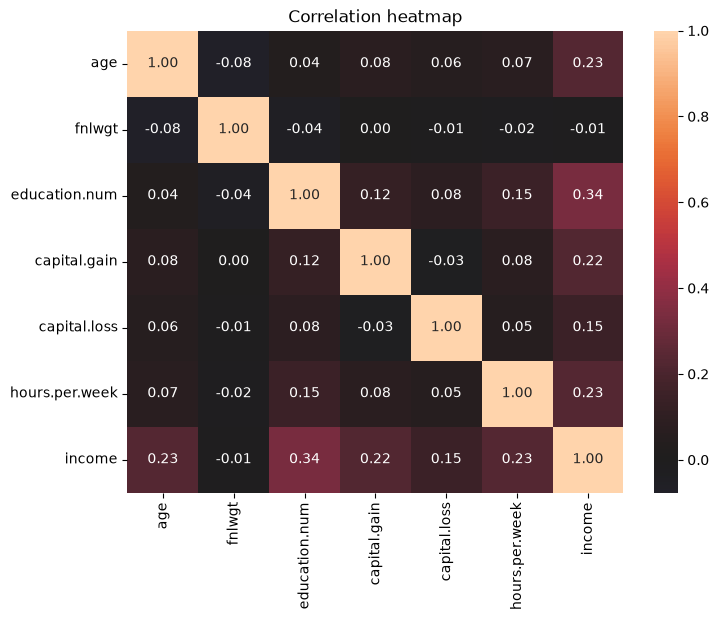

In [103]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", center=0)
plt.title("Correlation heatmap")
plt.show()

In [104]:
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
df.shape

(32537, 101)

In [105]:
df.isna().sum()

age                               0
fnlwgt                            0
education.num                     0
capital.gain                      0
capital.loss                      0
                                 ..
native.country_Trinadad&Tobago    0
native.country_United-States      0
native.country_Unknown            0
native.country_Vietnam            0
native.country_Yugoslavia         0
Length: 101, dtype: int64

In [106]:
bool_cols = df.select_dtypes(include="bool").columns

df[bool_cols]=df[bool_cols].astype(int)

In [107]:
df

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,income,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Unknown,native.country_Vietnam,native.country_Yugoslavia
0,90,77053,9,0,4356,40,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,82,132870,9,0,4356,18,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
2,66,186061,10,0,4356,40,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,54,140359,4,0,3900,40,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
4,41,264663,10,0,3900,40,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,310152,10,0,0,40,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
32557,27,257302,12,0,0,38,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
32558,40,154374,9,0,0,40,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
32559,58,151910,9,0,0,40,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0


In [108]:
df.isna().sum()

age                               0
fnlwgt                            0
education.num                     0
capital.gain                      0
capital.loss                      0
                                 ..
native.country_Trinadad&Tobago    0
native.country_United-States      0
native.country_Unknown            0
native.country_Vietnam            0
native.country_Yugoslavia         0
Length: 101, dtype: int64

### Models

- Separate features and target

In [110]:

y = df['income']

X = df.drop('income', axis=1)
X = pd.get_dummies(X, drop_first=True)

print('Features shape:', X.shape)
print(y.value_counts())

Features shape: (32537, 100)
income
0    24698
1     7839
Name: count, dtype: int64


- Train-Test Split And Scaling

In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train size:', X_train.shape[0])
print('Test size :', X_test.shape[0])

Train size: 26029
Test size : 6508


- Logistic Regression

In [113]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)
log_acc = accuracy_score(y_test, log_pred)

print('Logistic Regression Accuracy:', round(log_acc, 4))


Logistic Regression Accuracy: 0.8519


- Decision Tree

In [114]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_acc = accuracy_score(y_test, dt_pred)

print('Decision Tree Accuracy:', round(dt_acc, 4))

Decision Tree Accuracy: 0.848


- Random Forest

In [115]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print('Random Forest Accuracy:', round(rf_acc, 4))

Random Forest Accuracy: 0.8496


- KNN

In [116]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)
knn_acc = accuracy_score(y_test, knn_pred)

print('KNN Accuracy:', round(knn_acc, 4))

KNN Accuracy: 0.8181


- Comparison

In [117]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN'],
    'Accuracy': [log_acc, dt_acc, rf_acc, knn_acc]
}).sort_values('Accuracy', ascending=False)

print(results.to_string(index=False))

              Model  Accuracy
Logistic Regression  0.851875
      Random Forest  0.849570
      Decision Tree  0.848033
                KNN  0.818070


In [118]:
import joblib

final_model = log_model     
final_scaler = scaler     

joblib.dump(
    {"model": final_model, "scaler": final_scaler, "columns": list(X.columns)},
    "income_model.pkl",
)
print("Saved income_model.pkl")

Saved income_model.pkl
